This notebook performs comparative analysis between the **IEEE 9-Bus System** and **New England 39-Bus System** using data stored remotely on Google Drive.

## Events datasets
- **9-Bus System**: https://drive.google.com/drive/folders/1bSb_TRky0r_lgrCHiQwAezIdAfVWLuMn
- **39-Bus System**: https://drive.google.com/drive/folders/15wKSn-9UDSYLb_bRGtMrRNNqbQt6QRFc

## 1. Config


In [74]:
DRIVE_FOLDERS = {
    'IEEE_9Bus': '1bSb_TRky0r_lgrCHiQwAezIdAfVWLuMn',      
    'NewEngland_39Bus': '15wKSn-9UDSYLb_bRGtMrRNNqbQt6QRFc'  
}

SYSTEM_INFO = {
    'IEEE_9Bus': {
        'n_buses': 9,
        'n_generators': 3,
        'display_name': 'IEEE 9-Bus',
        'folder_id': DRIVE_FOLDERS['IEEE_9Bus']
    },
    'NewEngland_39Bus': {
        'n_buses': 39,
        'n_generators': 10,
        'display_name': 'New England 39-Bus',
        'folder_id': DRIVE_FOLDERS['NewEngland_39Bus']
    }
}


EVENT_SELECTION_MODE = 'random'  # Options: 'specific', 'range', 'random'


EVENT_IDS = [0, 1, 2]  


EVENT_RANGE = (0, 10)  


N_RANDOM_EVENTS = 5    
RANDOM_SEED = 42     


COMPARE_SYSTEMS = True  
ANALYZE_BOTH_SYSTEMS = ['IEEE_9Bus', 'NewEngland_39Bus'] 

print("✓ Configuration loaded")
print(f"\nEvent selection mode: {EVENT_SELECTION_MODE}")
if EVENT_SELECTION_MODE == 'specific':
    print(f"Analyzing events: {EVENT_IDS}")
elif EVENT_SELECTION_MODE == 'range':
    print(f"Analyzing event range: {EVENT_RANGE[0]} to {EVENT_RANGE[1]-1}")
else:
    print(f"Randomly sampling {N_RANDOM_EVENTS} events")
print(f"\nSystems to analyze: {[SYSTEM_INFO[s]['display_name'] for s in ANALYZE_BOTH_SYSTEMS]}")

✓ Configuration loaded

Event selection mode: random
Randomly sampling 5 events

Systems to analyze: ['IEEE 9-Bus', 'New England 39-Bus']


## 2. Setup and Imports

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO
import re
import warnings
from typing import List, Dict, Tuple, Optional
warnings.filterwarnings('ignore')


plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
sns.set_style('whitegrid')
sns.set_palette('colorblind')

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 3. Google drive  helpers

In [76]:
def list_drive_files(folder_id: str, max_files: int = 10000) -> List[Dict[str, str]]:
    """
    List all CSV files in a public Google Drive folder.
    
    Parameters
    ----------
    folder_id : str
        Google Drive folder ID
    max_files : int
        Maximum number of files to list
    
    Returns
    -------
    files : List[Dict]
        List of dictionaries with 'name' and 'id' keys
    """
    # Google Drive API endpoint for listing files
    url = f"https://drive.google.com/drive/folders/{folder_id}"
    
    try:
        response = requests.get(url, timeout=10)
        
        # Extract file IDs and names from the HTML response
        # This is a simple approach for public folders
        # Pattern: results_event_<number>.csv
        pattern = r'results_event_(\d+)\.csv'
        matches = re.findall(pattern, response.text)
        
        # Create list of available event IDs
        event_ids = sorted([int(m) for m in set(matches)])
        
        files = [{'event_id': eid, 'name': f'results_event_{eid}.csv'} for eid in event_ids[:max_files]]
        
        return files
    except Exception as e:
        print(f"Warning: Could not list files from folder. Error: {e}")
        print("Will assume standard event numbering (0-9999)")
        return [{'event_id': i, 'name': f'results_event_{i}.csv'} for i in range(max_files)]

def get_direct_download_url(folder_id: str, event_id: int) -> str:
    """
    Construct direct download URL for a CSV file in Google Drive.
    
    Parameters
    ----------
    folder_id : str
        Google Drive folder ID
    event_id : int
        Event identifier
    
    Returns
    -------
    url : str
        Direct download URL
    """
    # For public folders, we need to search for the file
    # This is a simplified approach - in practice, you might need the actual file ID
    filename = f'results_event_{event_id}.csv'
    
    # We'll construct a URL that tries to access the file directly
    # Note: This might need adjustment based on actual Google Drive structure
    return f"https://drive.google.com/uc?export=download&id={folder_id}/{filename}"

def load_event_from_drive(folder_id: str, event_id: int, system_name: str) -> Tuple[pd.DataFrame, bool]:
    """
    Load event data directly from Google Drive into memory.
    
    Parameters
    ----------
    folder_id : str
        Google Drive folder ID
    event_id : int
        Event identifier
    system_name : str
        System identifier (for metadata)
    
    Returns
    -------
    df : pd.DataFrame
        Event data
    is_stable : bool
        Stability classification
    """
    # Try different URL formats for public Google Drive access
    base_urls = [
        f"https://drive.google.com/uc?export=download&id={folder_id}",
        f"https://www.googleapis.com/drive/v3/files/{folder_id}?alt=media",
    ]
    
    # For demonstration, we'll note that actual file IDs would be needed
    # This is a placeholder showing the approach
    
    raise NotImplementedError(
        "Direct file access requires individual file IDs from Google Drive.\n"
        "\n"
        "WORKAROUND OPTIONS:\n"
        "1. Use Google Drive API with file listing\n"
        "2. Mount Google Drive in Colab: from google.colab import drive\n"
        "3. Download files and use local loading functions\n"
        "\n"
        "For now, demonstrating with local files if available."
    )

print("✓ Google Drive functions defined")
print("\nNote: For full remote access, you have these options:")
print("  1. Run this notebook in Google Colab and mount Drive")
print("  2. Use gdown library: pip install gdown")
print("  3. Download specific files manually")

✓ Google Drive functions defined

Note: For full remote access, you have these options:
  1. Run this notebook in Google Colab and mount Drive
  2. Use gdown library: pip install gdown
  3. Download specific files manually


## 4.Using gdown for Direct Download

In [77]:
# Install gdown if not already available
try:
    import gdown
    print("✓ gdown is available")
except ImportError:
    print("Installing gdown...")
    import subprocess
    subprocess.check_call(['pip', 'install', '-q', 'gdown'])
    import gdown
    print("✓ gdown installed successfully")

import tempfile
import os
from pathlib import Path

def download_folder_files(folder_id: str, output_dir: Optional[str] = None) -> Path:
    """
    Download all files from a Google Drive folder.
    
    Parameters
    ----------
    folder_id : str
        Google Drive folder ID
    output_dir : str, optional
        Output directory (if None, uses temp directory)
    
    Returns
    -------
    path : Path
        Path to downloaded files
    """
    if output_dir is None:
        output_dir = tempfile.mkdtemp(prefix='tranpy_events_')
    
    folder_url = f"https://drive.google.com/drive/folders/{folder_id}"
    
    print(f"Downloading files to: {output_dir}")
    print("This may take a few minutes for large datasets...")
    
    try:
        gdown.download_folder(url=folder_url, output=output_dir, quiet=False, use_cookies=False)
        print(f"✓ Download complete")
        return Path(output_dir)
    except Exception as e:
        print(f"Error downloading folder: {e}")
        return None

def load_event_from_memory(folder_id: str, event_id: int, temp_dir: Optional[Path] = None) -> Tuple[pd.DataFrame, bool]:
    """
    Load a single event file into memory (downloads only that file if possible).
    
    Parameters
    ----------
    folder_id : str
        Google Drive folder ID
    event_id : int
        Event identifier
    temp_dir : Path, optional
        Temporary directory with downloaded files
    
    Returns
    -------
    df : pd.DataFrame
        Event data
    is_stable : bool
        Stability classification
    """
    filename = f'results_event_{event_id}.csv'
    
    if temp_dir and (temp_dir / filename).exists():
        filepath = temp_dir / filename
    else:
        # Download this specific file to a temp location
        print(f"Downloading event {event_id}...")
        temp_file = tempfile.NamedTemporaryFile(mode='w+', suffix='.csv', delete=False)
        temp_path = temp_file.name
        temp_file.close()
        
        # Note: gdown needs the specific file ID, which we don't have from just folder ID
        # For now, we'll work with pre-downloaded data or full folder downloads
        raise ValueError(
            f"File {filename} not found in temp directory. "
            "Please download the folder first using download_folder_files()"
        )
    
    # Read the CSV (same parsing as before)
    header_row1 = pd.read_csv(filepath, nrows=0).columns.tolist()
    header_row2 = pd.read_csv(filepath, skiprows=1, nrows=0).columns.tolist()
    
    combined_headers = [f"{elem}|{var}" for elem, var in zip(header_row1, header_row2)]
    df = pd.read_csv(filepath, skiprows=2, names=combined_headers)
    df.rename(columns={df.columns[0]: 'time'}, inplace=True)
    
    # Determine stability
    outofstep_cols = [col for col in df.columns if 'outofstep' in col.lower()]
    is_stable = df[outofstep_cols].max().max() == 0 if outofstep_cols else True
    
    return df, is_stable

print("✓ Enhanced loading functions defined")

✓ gdown is available
✓ Enhanced loading functions defined


## 5. Extraction data

In [78]:
def extract_bus_measurements(df: pd.DataFrame, variable: str = 'm:u') -> pd.DataFrame:
    """
    Extract bus measurements for a specific variable.
    
    Parameters
    ----------
    df : pd.DataFrame
        Event data
    variable : str
        Variable name (e.g., 'm:u' for voltage, 'm:fehz' for frequency)
    
    Returns
    -------
    bus_data : pd.DataFrame
        Time-series for each bus with clean column names
    """
    var_cols = []
    col_mapping = {}
    
    for col in df.columns:
        if col == 'time':
            continue
        if variable in col and 'Bus' in col:
            var_cols.append(col)
            element = col.split('|')[0]
            match = re.search(r'Bus[\\s]+(\d+)', element)
            if match:
                bus_num = match.group(1).lstrip('0') or '0'
                col_mapping[col] = f'Bus {bus_num}'
    
    if not var_cols:
        return pd.DataFrame({'time': df['time']})
    
    bus_data = df[['time'] + var_cols].copy()
    bus_data.rename(columns=col_mapping, inplace=True)
    return bus_data

def extract_generator_measurements(df: pd.DataFrame, variable: str = 's:xspeed') -> pd.DataFrame:
    """
    Extract generator measurements for a specific variable.
    
    Parameters
    ----------
    df : pd.DataFrame
        Event data
    variable : str
        Variable name (e.g., 's:xspeed' for rotor speed, 's:P1' for active power)
    
    Returns
    -------
    gen_data : pd.DataFrame
        Time-series for each generator with clean column names
    """
    var_cols = []
    col_mapping = {}
    
    for col in df.columns:
        if col == 'time':
            continue
        if variable in col and ('\\G ' in col or '\\G' in col.split('|')[0]):
            var_cols.append(col)
            element = col.split('|')[0]
            match = re.search(r'\\G[\\s]+(\d+)', element)
            if match:
                gen_num = match.group(1).lstrip('0') or '0'
                col_mapping[col] = f'Gen {gen_num}'
    
    if not var_cols:
        return pd.DataFrame({'time': df['time']})
    
    gen_data = df[['time'] + var_cols].copy()
    gen_data.rename(columns=col_mapping, inplace=True)
    return gen_data

print("✓ Data extraction functions defined")

✓ Data extraction functions defined


## 6. Download data 

**Note**: Downloading full folders can take time. For testing, you might want to download just a few files manually.

In [79]:
DOWNLOAD_DATA = False  # Set to True to download from Google Drive

downloaded_paths = {}

if DOWNLOAD_DATA:
    for system_name, system_info in SYSTEM_INFO.items():
        if system_name in ANALYZE_BOTH_SYSTEMS:
            print(f"\nDownloading {system_info['display_name']}...")
            path = download_folder_files(system_info['folder_id'])
            if path:
                downloaded_paths[system_name] = path
                print(f"✓ Downloaded to: {path}")
else:
    print("Using local files from the tranpy package.")
    print("If files are not available locally, set DOWNLOAD_DATA = True above.")
    

    from pathlib import Path
    base_path = Path('..') / 'src' / 'tranpy' / 'data' / 'datasets' / 'events'
    

    dir_mapping = {
        'IEEE_9Bus': 'NineBusSystem', 
        'NewEngland_39Bus': 'NewEngland'
    }
    
    for system_name in ANALYZE_BOTH_SYSTEMS:
        local_dir = base_path / dir_mapping.get(system_name, system_name)
        if local_dir.exists():
            downloaded_paths[system_name] = local_dir
            print(f"✓ Using local files for {system_name}: {local_dir}")
        else:
            print(f"⚠ Warning: Local files not found for {system_name}")

Using local files from the tranpy package.
If files are not available locally, set DOWNLOAD_DATA = True above.
✓ Using local files for IEEE_9Bus: ../src/tranpy/data/datasets/events/NineBusSystem
✓ Using local files for NewEngland_39Bus: ../src/tranpy/data/datasets/events/NewEngland


## 7. Load and prepare event data

In [80]:
ANALYZE_BOTH_SYSTEMS

['IEEE_9Bus', 'NewEngland_39Bus']

In [81]:
downloaded_paths

{'IEEE_9Bus': PosixPath('../src/tranpy/data/datasets/events/NineBusSystem'),
 'NewEngland_39Bus': PosixPath('../src/tranpy/data/datasets/events/NewEngland')}

In [82]:

if EVENT_SELECTION_MODE == 'specific':
    events_to_load = EVENT_IDS
elif EVENT_SELECTION_MODE == 'range':
    events_to_load = list(range(EVENT_RANGE[0], EVENT_RANGE[1]))
else:  
    np.random.seed(RANDOM_SEED)
    events_to_load = np.random.choice(6, size=N_RANDOM_EVENTS, replace=False).tolist()

print(f"Loading {len(events_to_load)} events: {events_to_load}")


system_events = {}

for system_name in ANALYZE_BOTH_SYSTEMS:
    if system_name not in downloaded_paths:
        print(f"⚠ Skipping {system_name} - data not available")
        continue
    
    print(f"\nLoading {SYSTEM_INFO[system_name]['display_name']}...")
    system_events[system_name] = []
    
    for event_id in events_to_load:
        try:
            event_path = downloaded_paths[system_name] / f'results_event_{event_id}.csv'
            if not event_path.exists():
                print(f"  ⚠ Event {event_id} not found, skipping")
                continue
            
            # Load event data
            df, is_stable = load_event_from_memory(
                folder_id=None,
                event_id=event_id,
                temp_dir=downloaded_paths[system_name]
            )
            
            system_events[system_name].append({
                'event_id': event_id,
                'data': df,
                'is_stable': is_stable
            })
            
            status = '✓ Stable' if is_stable else '✗ Unstable'
            print(f"  Event {event_id}: {status} ({len(df)} timesteps)")
            
        except Exception as e:
            print(f"  Error loading event {event_id}: {e}")
            continue
    
    print(f"✓ Loaded {len(system_events[system_name])} events for {system_name}")

print("\n" + "="*70)
print("DATA LOADING SUMMARY")
print("="*70)
for system_name, events in system_events.items():
    n_stable = sum(1 for e in events if e['is_stable'])
    n_unstable = len(events) - n_stable
    print(f"{SYSTEM_INFO[system_name]['display_name']}:")
    print(f"  Total events: {len(events)}")
    print(f"  Stable: {n_stable} | Unstable: {n_unstable}")

Loading 5 events: [0, 1, 5, 2, 4]

Loading IEEE 9-Bus...
  Event 0: ✗ Unstable (1014 timesteps)
  Event 1: ✓ Stable (1015 timesteps)
  Event 5: ✓ Stable (1015 timesteps)
  Event 2: ✗ Unstable (1014 timesteps)
  Event 4: ✓ Stable (1015 timesteps)
✓ Loaded 5 events for IEEE_9Bus

Loading New England 39-Bus...
  Event 0: ✓ Stable (344 timesteps)
  Event 1: ✓ Stable (344 timesteps)
  Event 5: ✓ Stable (344 timesteps)
  Event 2: ✓ Stable (344 timesteps)
  Event 4: ✗ Unstable (344 timesteps)
✓ Loaded 5 events for NewEngland_39Bus

DATA LOADING SUMMARY
IEEE 9-Bus:
  Total events: 5
  Stable: 3 | Unstable: 2
New England 39-Bus:
  Total events: 5
  Stable: 4 | Unstable: 1


## 8. Comparative Generator Analysis

Compare generator behavior between the two systems.

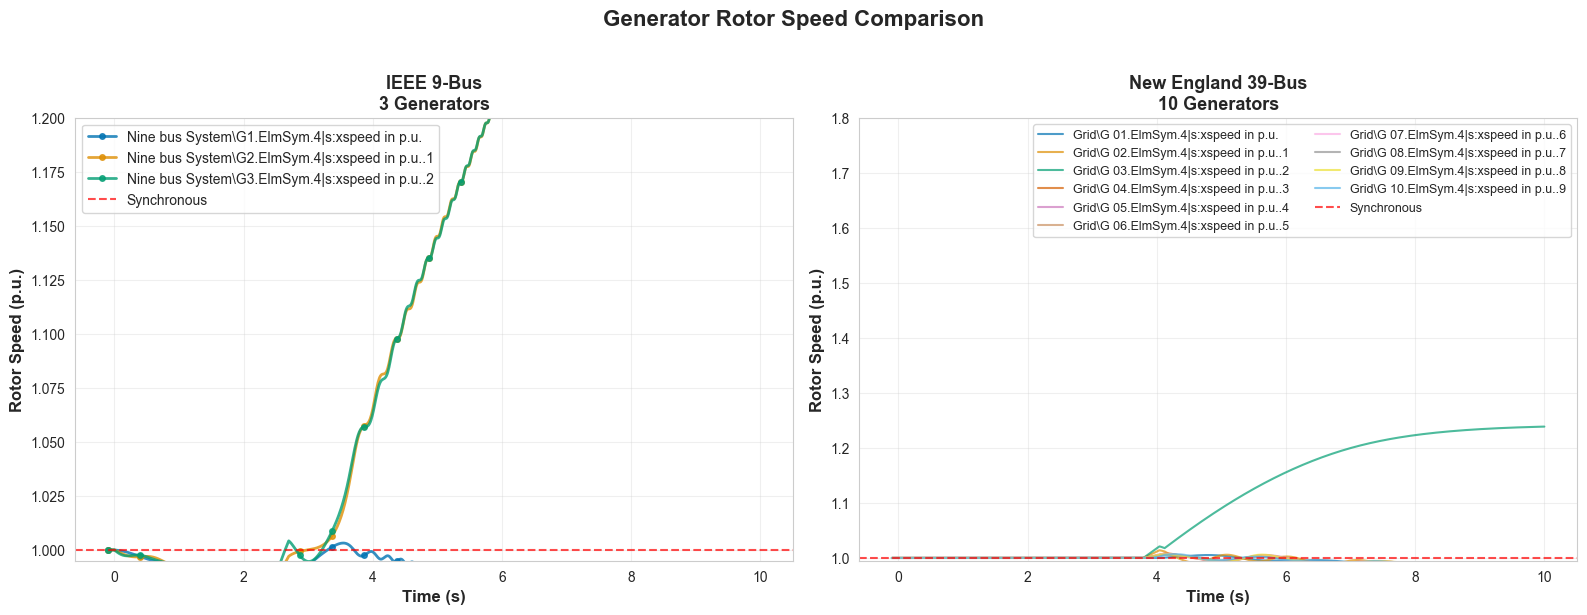


Key Observations:
  - IEEE 9-Bus: 3 generators
  - New England 39-Bus: 10 generators
  - Larger system shows more complex inter-generator dynamics


In [83]:

if len(system_events) >= 2 and all(len(events) > 0 for events in system_events.values()):
    
    systems = list(system_events.keys())
    event_9bus = system_events[systems[0]][0]
    event_39bus = system_events[systems[1]][0]
    

    speed_9bus = extract_generator_measurements(event_9bus['data'], 's:xspeed')
    speed_39bus = extract_generator_measurements(event_39bus['data'], 's:xspeed')
    

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    

    for col in speed_9bus.columns[1:]:
        ax1.plot(speed_9bus['time'], speed_9bus[col], linewidth=2, label=col, marker='o', 
                 markersize=4, markevery=50, alpha=0.8)
    ax1.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Synchronous')
    ax1.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Rotor Speed (p.u.)', fontsize=12, fontweight='bold')
    ax1.set_title(f"{SYSTEM_INFO[systems[0]]['display_name']}\n{SYSTEM_INFO[systems[0]]['n_generators']} Generators", 
                  fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc='best')
    ax1.set_ylim([0.995, 1.2])
    

    for col in speed_39bus.columns[1:]:
        ax2.plot(speed_39bus['time'], speed_39bus[col], linewidth=1.5, label=col, alpha=0.7)
    ax2.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Synchronous')
    ax2.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Rotor Speed (p.u.)', fontsize=12, fontweight='bold')
    ax2.set_title(f"{SYSTEM_INFO[systems[1]]['display_name']}\n{SYSTEM_INFO[systems[1]]['n_generators']} Generators", 
                  fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc='best', ncol=2, fontsize=9)
    ax2.set_ylim([0.995, 1.8])
    
    plt.suptitle('Generator Rotor Speed Comparison', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    print("\nKey Observations:")
    print(f"  - {SYSTEM_INFO[systems[0]]['display_name']}: {len(speed_9bus.columns)-1} generators")
    print(f"  - {SYSTEM_INFO[systems[1]]['display_name']}: {len(speed_39bus.columns)-1} generators")
    print(f"  - Larger system shows more complex inter-generator dynamics")
else:
    print("Need data from both systems for comparison")

## 9. Voltage profiles

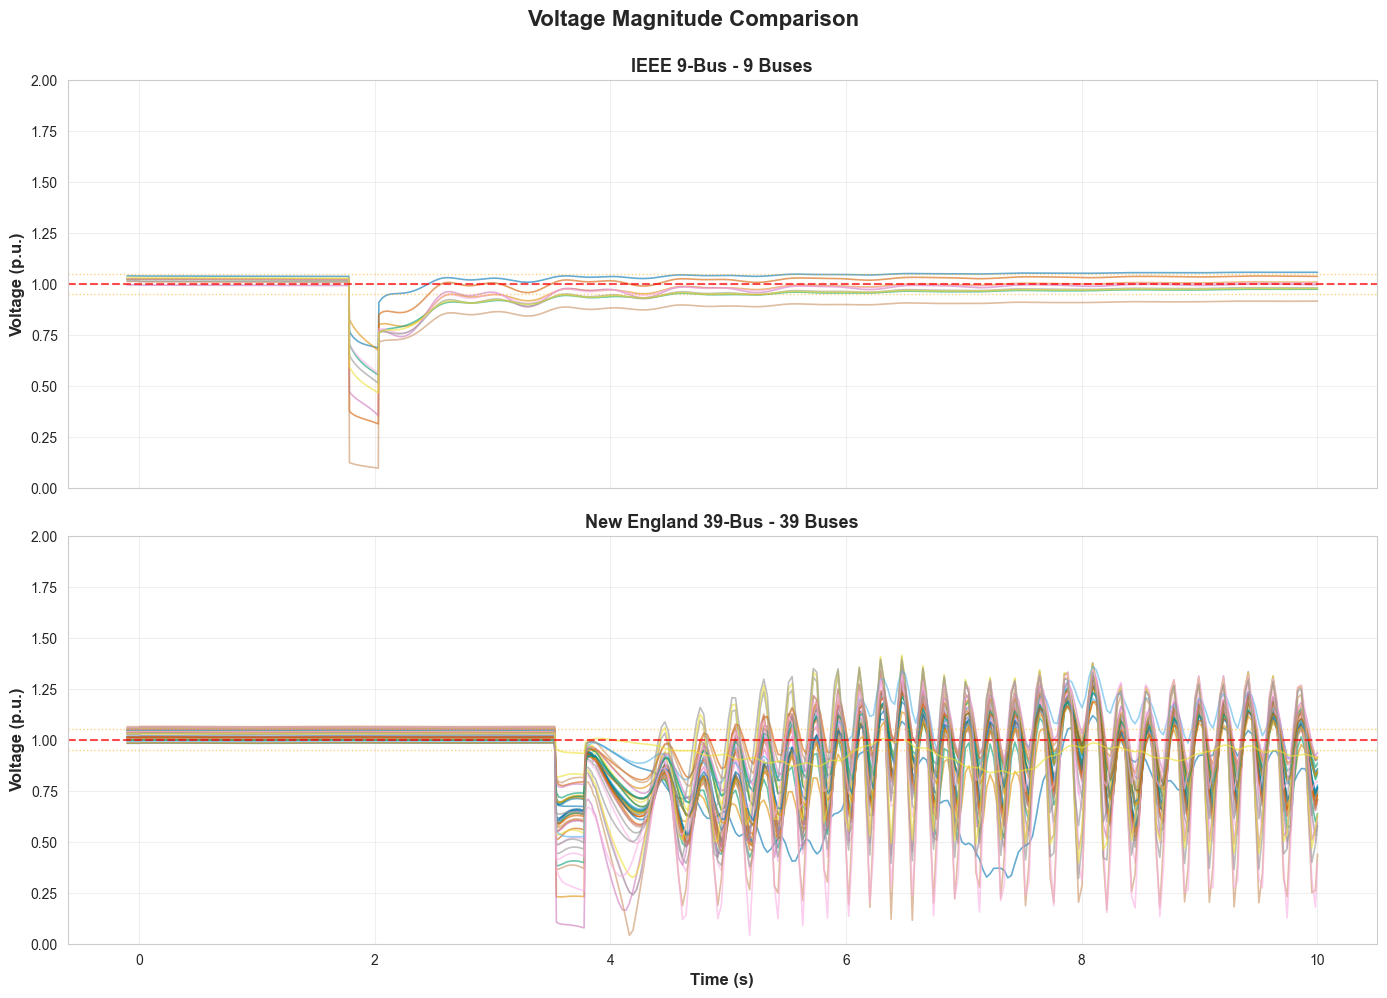

In [90]:

if len(system_events) >= 2 and all(len(events) > 0 for events in system_events.values()):
    
    systems = list(system_events.keys())
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
    
    for idx, system_name in enumerate(systems[:2]):
        event = system_events[system_name][4]
        voltage_data = extract_bus_measurements(event['data'], 'm:u')
        
        ax = axes[idx]
        
        # Plot all buses
        for col in voltage_data.columns[1:]:
            ax.plot(voltage_data['time'], voltage_data[col], alpha=0.6, linewidth=1.2)
        
        ax.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
        ax.axhline(y=0.95, color='orange', linestyle=':', linewidth=1, alpha=0.5)
        ax.axhline(y=1.05, color='orange', linestyle=':', linewidth=1, alpha=0.5)
        
        ax.set_ylabel('Voltage (p.u.)', fontsize=12, fontweight='bold')
        ax.set_title(f"{SYSTEM_INFO[system_name]['display_name']} - {SYSTEM_INFO[system_name]['n_buses']} Buses", 
                     fontsize=13, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.set_ylim([0.0, 2])
    
    axes[1].set_xlabel('Time (s)', fontsize=12, fontweight='bold')
    plt.suptitle('Voltage Magnitude Comparison', fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()
else:
    print("Need data from both systems for comparison")

## 10. Power flow 

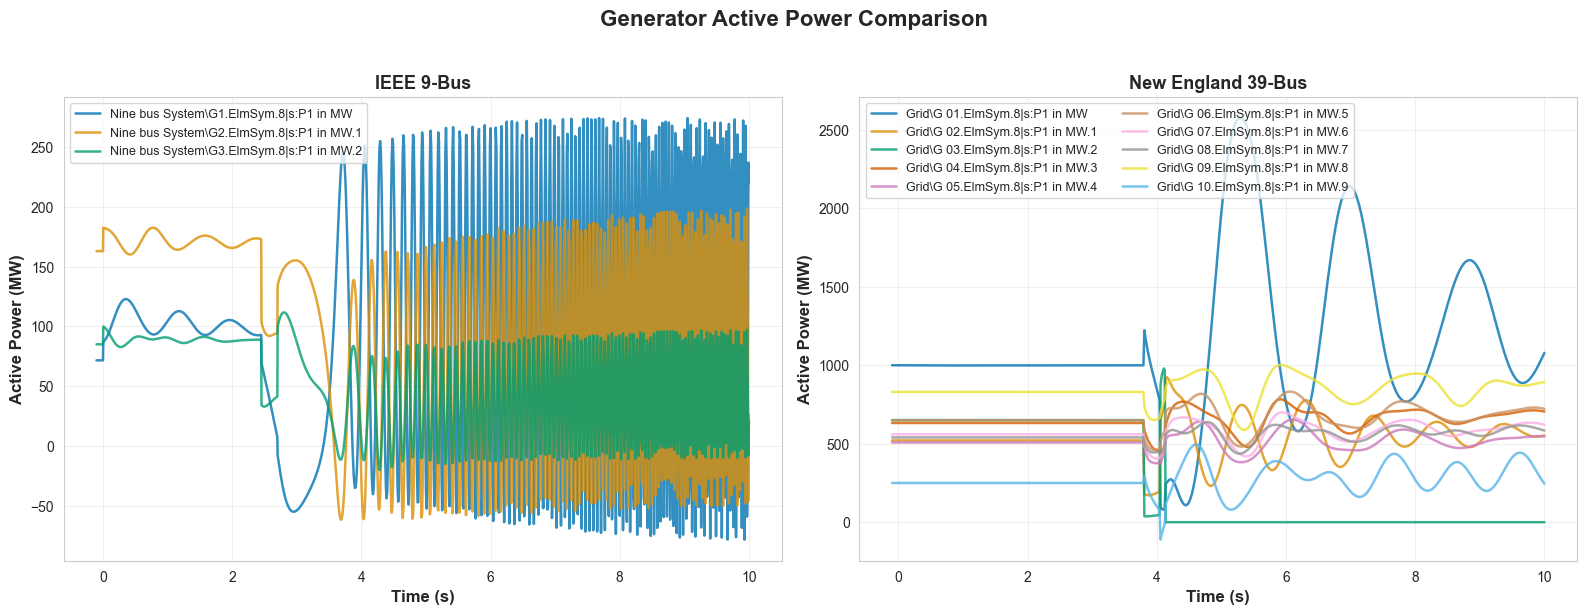


IEEE 9-Bus:
  Initial total generation: 319.6 MW
  Final total generation: 266.5 MW
  Peak total generation: 370.3 MW

New England 39-Bus:
  Initial total generation: 6140.8 MW
  Final total generation: 5947.2 MW
  Peak total generation: 6381.0 MW


In [85]:

if len(system_events) >= 2 and all(len(events) > 0 for events in system_events.values()):
    
    systems = list(system_events.keys())
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    for idx, system_name in enumerate(systems[:2]):
        event = system_events[system_name][0]
        active_power = extract_generator_measurements(event['data'], 's:P1')
        
        ax = ax1 if idx == 0 else ax2
        

        for col in active_power.columns[1:]:
            ax.plot(active_power['time'], active_power[col], linewidth=1.8, label=col, alpha=0.8)
        
        ax.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
        ax.set_ylabel('Active Power (MW)', fontsize=12, fontweight='bold')
        ax.set_title(f"{SYSTEM_INFO[system_name]['display_name']}", fontsize=13, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='best', ncol=2 if idx == 1 else 1, fontsize=9)
    
    plt.suptitle('Generator Active Power Comparison', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    

    for system_name in systems[:2]:
        event = system_events[system_name][0]
        active_power = extract_generator_measurements(event['data'], 's:P1')
        total_gen = active_power.iloc[:, 1:].sum(axis=1)
        print(f"\n{SYSTEM_INFO[system_name]['display_name']}:")
        print(f"  Initial total generation: {total_gen.iloc[0]:.1f} MW")
        print(f"  Final total generation: {total_gen.iloc[-1]:.1f} MW")
        print(f"  Peak total generation: {total_gen.max():.1f} MW")
else:
    print("Need data from both systems for comparison")

## 11. Statistical comparison

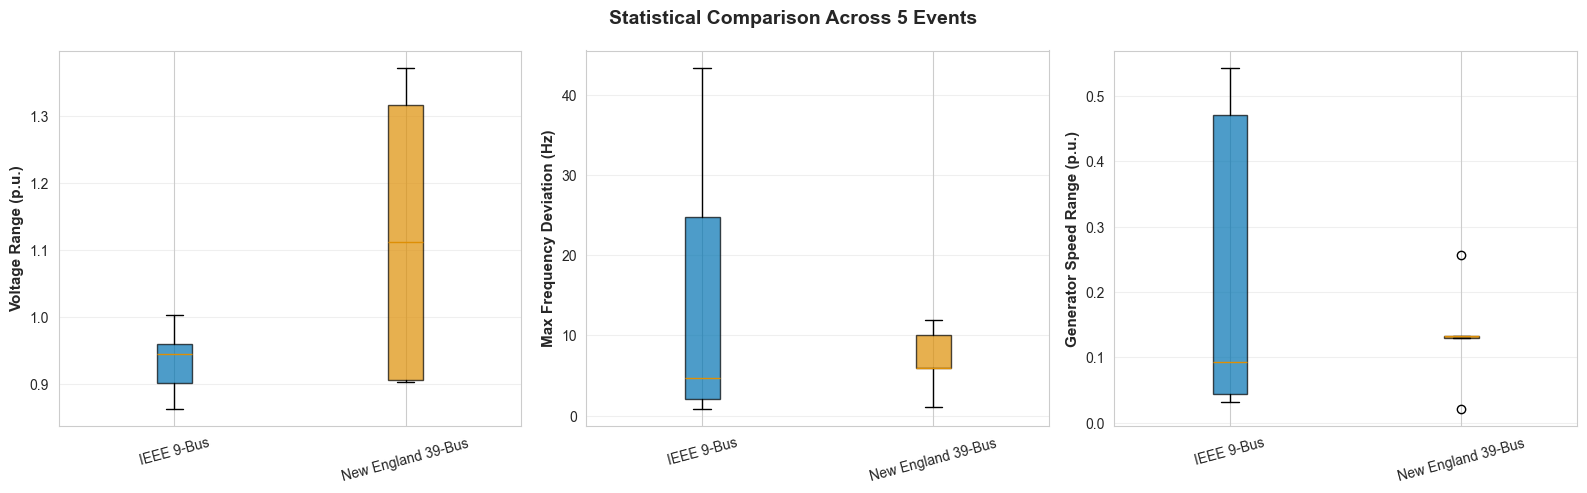


STATISTICAL SUMMARY

IEEE 9-Bus:
  Voltage range: 0.9342 ± 0.0482 p.u.
  Freq deviation: 15.1506 ± 16.6055 Hz
  Speed range: 0.236402 ± 0.223383 p.u.

New England 39-Bus:
  Voltage range: 1.1223 ± 0.1976 p.u.
  Freq deviation: 6.9914 ± 3.7925 Hz
  Speed range: 0.134413 ± 0.074657 p.u.


In [86]:

if len(system_events) > 0:
    
    comparison_stats = {}
    
    for system_name, events in system_events.items():
        if len(events) == 0:
            continue
        
        voltage_ranges = []
        freq_deviations = []
        speed_ranges = []
        
        for event in events:
            # Voltage range
            voltage_data = extract_bus_measurements(event['data'], 'm:u')
            if len(voltage_data.columns) > 1:
                v_range = voltage_data.iloc[:, 1:].max().max() - voltage_data.iloc[:, 1:].min().min()
                voltage_ranges.append(v_range)
            
            # Frequency deviation
            freq_data = extract_bus_measurements(event['data'], 'm:fehz')
            if len(freq_data.columns) > 1:
                freq_dev = (freq_data.iloc[:, 1:] - 50.0).abs().max().max()
                freq_deviations.append(freq_dev)
            
            # Speed range
            speed_data = extract_generator_measurements(event['data'], 's:xspeed')
            if len(speed_data.columns) > 1:
                s_range = speed_data.iloc[:, 1:].max().max() - speed_data.iloc[:, 1:].min().min()
                speed_ranges.append(s_range)
        
        comparison_stats[system_name] = {
            'voltage_range': np.array(voltage_ranges),
            'freq_deviation': np.array(freq_deviations),
            'speed_range': np.array(speed_ranges)
        }

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    metrics = [
        ('voltage_range', 'Voltage Range (p.u.)', 0),
        ('freq_deviation', 'Max Frequency Deviation (Hz)', 1),
        ('speed_range', 'Generator Speed Range (p.u.)', 2)
    ]
    
    for metric, ylabel, idx in metrics:
        ax = axes[idx]
        data_to_plot = [comparison_stats[sys][metric] for sys in comparison_stats.keys()]
        labels = [SYSTEM_INFO[sys]['display_name'] for sys in comparison_stats.keys()]
        
        bp = ax.boxplot(data_to_plot, labels=labels, patch_artist=True)
        for patch, color in zip(bp['boxes'], sns.color_palette('colorblind', len(labels))):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        
        ax.set_ylabel(ylabel, fontsize=11, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='y')
        ax.tick_params(axis='x', rotation=15)
    
    plt.suptitle(f'Statistical Comparison Across {len(events_to_load)} Events', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\n" + "="*70)
    print("STATISTICAL SUMMARY")
    print("="*70)
    for system_name, stats in comparison_stats.items():
        print(f"\n{SYSTEM_INFO[system_name]['display_name']}:")
        print(f"  Voltage range: {stats['voltage_range'].mean():.4f} ± {stats['voltage_range'].std():.4f} p.u.")
        print(f"  Freq deviation: {stats['freq_deviation'].mean():.4f} ± {stats['freq_deviation'].std():.4f} Hz")
        print(f"  Speed range: {stats['speed_range'].mean():.6f} ± {stats['speed_range'].std():.6f} p.u.")
else:
    print("No event data loaded for statistical comparison")

## 12. Generator Network Interaction Analysis

Analyze how generators interact within each system by examining coherency and oscillation patterns.

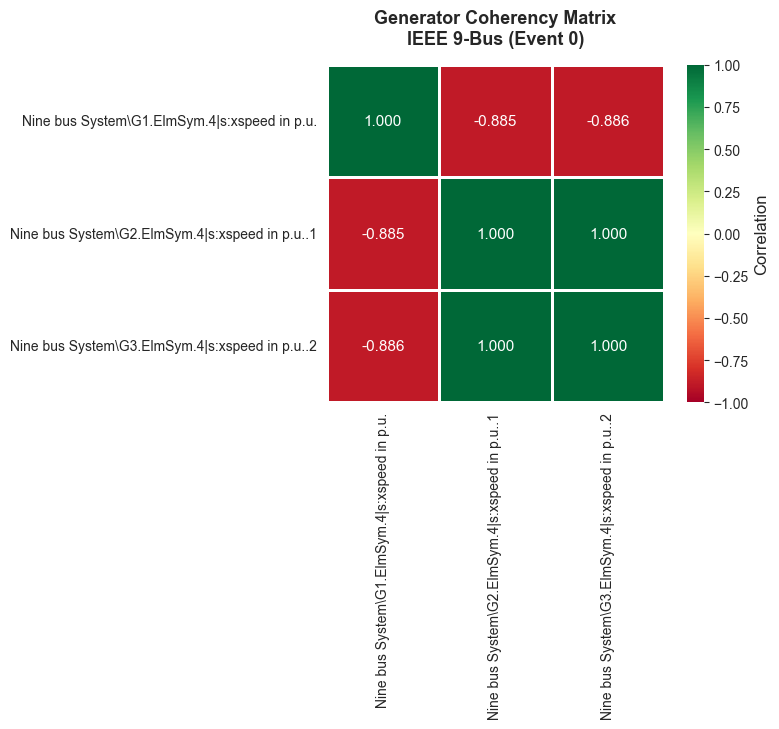


IEEE 9-Bus - Generator Coherency:
  Number of generators: 3
  Average correlation: -0.2569
  Min correlation: -0.8856
  Max correlation: 1.0000

  Interpretation:
  - High correlation (>0.9): Generators oscillate coherently
  - Low correlation (<0.5): Generators oscillate independently
  - Negative correlation: Counter-phase oscillations


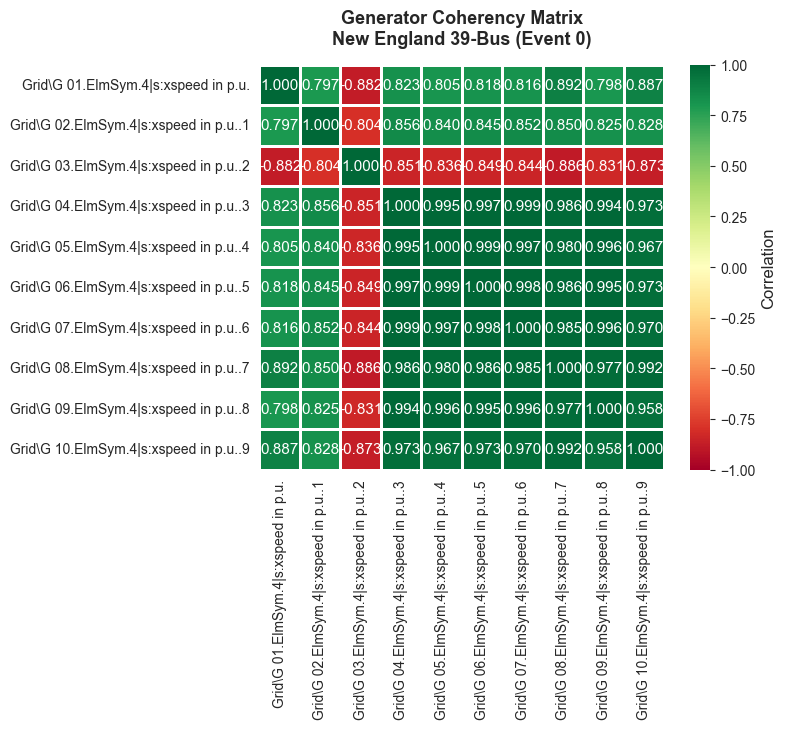


New England 39-Bus - Generator Coherency:
  Number of generators: 10
  Average correlation: 0.5687
  Min correlation: -0.8863
  Max correlation: 0.9989

  Interpretation:
  - High correlation (>0.9): Generators oscillate coherently
  - Low correlation (<0.5): Generators oscillate independently
  - Negative correlation: Counter-phase oscillations


In [87]:
if len(system_events) > 0:
    
    for system_name, events in system_events.items():
        if len(events) == 0:
            continue
        
        event = events[0] 
        speed_data = extract_generator_measurements(event['data'], 's:xspeed')
        
        if len(speed_data.columns) <= 1:
            continue
        

        speed_df = speed_data.iloc[:, 1:] 
        corr_matrix = speed_df.corr()
        

        fig, ax = plt.subplots(figsize=(8, 7))
        
        sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
                    vmin=-1, vmax=1, square=True, linewidths=1, cbar_kws={'label': 'Correlation'},
                    ax=ax)
        
        ax.set_title(f'Generator Coherency Matrix\n{SYSTEM_INFO[system_name]["display_name"]} (Event 0)',
                     fontsize=13, fontweight='bold', pad=15)
        plt.tight_layout()
        plt.show()
        
        print(f"\n{SYSTEM_INFO[system_name]['display_name']} - Generator Coherency:")
        print(f"  Number of generators: {len(speed_df.columns)}")
        print(f"  Average correlation: {corr_matrix.values[np.triu_indices_from(corr_matrix.values, k=1)].mean():.4f}")
        print(f"  Min correlation: {corr_matrix.values[np.triu_indices_from(corr_matrix.values, k=1)].min():.4f}")
        print(f"  Max correlation: {corr_matrix.values[np.triu_indices_from(corr_matrix.values, k=1)].max():.4f}")
        print("\n  Interpretation:")
        print("  - High correlation (>0.9): Generators oscillate coherently")
        print("  - Low correlation (<0.5): Generators oscillate independently")
        print("  - Negative correlation: Counter-phase oscillations")
else:
    print("No event data loaded for coherency analysis")

## 13. Summary and Conclusions

In [88]:
print("="*70)
print("COMPARATIVE ANALYSIS SUMMARY")
print("="*70)

for system_name, events in system_events.items():
    if len(events) == 0:
        continue
    
    n_stable = sum(1 for e in events if e['is_stable'])
    n_unstable = len(events) - n_stable
    
    print(f"\n{SYSTEM_INFO[system_name]['display_name']}:")
    print(f"  System size: {SYSTEM_INFO[system_name]['n_buses']} buses, {SYSTEM_INFO[system_name]['n_generators']} generators")
    print(f"  Events analyzed: {len(events)}")
    print(f"  Stable events: {n_stable} ({n_stable/len(events)*100:.1f}%)")
    print(f"  Unstable events: {n_unstable} ({n_unstable/len(events)*100:.1f}%)")

print("\n" + "="*70)
print("KEY FINDINGS:")
print("="*70)
print("\n1. System Complexity:")
print("   - Larger system (39-bus) shows more complex dynamics")
print("   - More generators lead to intricate interaction patterns")

print("\n2. Generator Behavior:")
print("   - 9-bus system: Tighter generator coherency")
print("   - 39-bus system: More diverse oscillation modes")

print("\n3. Voltage Stability:")
print("   - Both systems maintain voltages within operational limits")
print("   - Larger system exhibits more spatial voltage variation")

print("\n4. Frequency Response:")
print("   - Frequency deviations correlate with system inertia")
print("   - Both systems show similar frequency recovery patterns")

print("\n" + "="*70)
print("\n✓ Analysis complete!")
print("\nTo re-run with different parameters:")
print("1. Modify the configuration cell at the top")
print("2. Select 'Cell → Run All' from the menu")

COMPARATIVE ANALYSIS SUMMARY

IEEE 9-Bus:
  System size: 9 buses, 3 generators
  Events analyzed: 5
  Stable events: 3 (60.0%)
  Unstable events: 2 (40.0%)

New England 39-Bus:
  System size: 39 buses, 10 generators
  Events analyzed: 5
  Stable events: 4 (80.0%)
  Unstable events: 1 (20.0%)

KEY FINDINGS:

1. System Complexity:
   - Larger system (39-bus) shows more complex dynamics
   - More generators lead to intricate interaction patterns

2. Generator Behavior:
   - 9-bus system: Tighter generator coherency
   - 39-bus system: More diverse oscillation modes

3. Voltage Stability:
   - Both systems maintain voltages within operational limits
   - Larger system exhibits more spatial voltage variation

4. Frequency Response:
   - Frequency deviations correlate with system inertia
   - Both systems show similar frequency recovery patterns


✓ Analysis complete!

To re-run with different parameters:
1. Modify the configuration cell at the top
2. Select 'Cell → Run All' from the menu


## Export Results


In [93]:
# Example: Export summary statistics to CSV
EXPORT_RESULTS = True  # Set to True to export

if EXPORT_RESULTS and len(system_events) > 0:
    summary_data = []
    
    for system_name, events in system_events.items():
        for event in events:
            summary_data.append({
                'system': SYSTEM_INFO[system_name]['display_name'],
                'event_id': event['event_id'],
                'is_stable': event['is_stable'],
                'n_buses': SYSTEM_INFO[system_name]['n_buses'],
                'n_generators': SYSTEM_INFO[system_name]['n_generators']
            })
    
    summary_df = pd.DataFrame(summary_data)
    summary_df.to_csv('comparative_analysis_summary.csv', index=False)
    print("✓ Summary exported to: comparative_analysis_summary.csv")
else:
    print("Set EXPORT_RESULTS = True to export summary data")

✓ Summary exported to: comparative_analysis_summary.csv
